---
title: "Gebäudesektormodell Österreich 2040"
execute:
  echo: true
format:
  html:
    code-fold: true
jupyter: python3
---

# Gebäudesektormodell: Daten, Rechnung und Grenzen {#sec-gebaeudesektormodell}

## 1. Modellrolle und Bilanzgrenzen

Das Notebook ist die ausführbare Bottom-up-Seite der PEQ-Zielwertkalibrierung. Es verbindet die **gelieferte Flächenstruktur 2040** mit den energetischen Kennwerten der Archetypen und den österreichischen GFZ-Verteilungen. Die Top-down-Allokation steht in @sec-allokation-notebook. Ein Abgleich wird ausgewiesen, eine automatische Neukalibrierung findet nicht statt.

**Quelle:** `Building-Sector_Pool 1.xlsx`, Lieferung 23.10.2026. `Strombed_estim` ist maßgeblich für die 900 Typen und ihre Flächen; `zuordnung_gfz!A:F` für die Dichtezuordnung. `Tabelle2` liefert ergänzende Anwendungen und die Einheiten. Die unveränderte Quelldatei ist unter `data/` versioniert. `daten_gebauedesektor.xlsx` ist eine editierbare Reinschrift ihrer gespeicherten Werte. Die gespeicherten PEExcel-Ergebnisse werden geprüft, aber nicht neu simuliert.

Bezugsjahr ist **2040**. „Heute“ bleibt eine getrennte Quellspalte mit noch unbestätigtem Bezugsjahr. Sie ist **nicht automatisch 2020**. Für 2020 gibt es ein leeres ergänzbares Flächenfeld. Auch die heutige Spalte wird mit denselben gelieferten Typenkennwerten ausgewertet und ist daher keine unabhängig validierte historische Energiebilanz.

Flächen: BGF in m², spezifische Energien laut `Tabelle2` in kWh/(m² NGF·a). Der aus der vorhandenen GFZ-Analyse übernommene Faktor $r=A_{NGF}/A_{BGF}=0{,}8$ ist eine einheitliche Modellannahme, keine typologiespezifische Messung. $1\,GWh=10^6\,kWh$, $1\,PJ=10^9/3{,}6\,kWh$. Salden sind **Erzeugung bzw. Export minus Bedarf bzw. Import**. Mobilität ist in den gelieferten Simulationskennwerten null und wird erst beim Top-down-Vergleich separat angesetzt. Virtuelle Dichtewerte bleiben von physischen Energieflüssen getrennt.

In [1]:
from pathlib import Path
import sys, json, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'_quarto.yml').exists())
BASE=ROOT/'Berechnungen/gebaeudesektormodell'
sys.path.insert(0,str(BASE))
from utils import read_source, sha256, markdown_table
OUT=BASE/'outputs'; OUT.mkdir(exist_ok=True)
GEN=ROOT/'Kapitel/_generated'; GEN.mkdir(exist_ok=True)
SOURCE=BASE/'data/Building-Sector_Pool_1.xlsx'
INPUT=BASE/'daten_gebauedesektor.xlsx'
source=read_source(SOURCE)
inputs=pd.read_excel(INPUT,sheet_name=None)
types=inputs['Typen'].copy()
applications=inputs['Anwendungen'].copy()
params=inputs['Parameter'].set_index('Parameter')['Wert'].to_dict()
r=float(params['ngf_bgf']); assert 0<r<=1
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_columns',12)
provenance={'source_sha256':sha256(SOURCE),'input_sha256':sha256(INPUT),
 'gfz_sha256':sha256(ROOT/'Berechnungen/gfz_at/outputs/recalculated/gfz_distribution_by_province_use_storeys.csv')}
display(pd.DataFrame(list(provenance.items()),columns=['Datei','SHA256']))

,Datei,SHA256
0,source_sha256,b032c1bd7148b0bdac8541196a1eaa7fc58f538f87912e...
1,input_sha256,cd09efbfbea7bc7e8cfd82b07146f72c6f3712d3a38162...
2,gfz_sha256,b17c1f98b6104a5b8ed6da4fe436ebff14d2f7708cc204...


## 2. Datenprüfung, Schlüssel und Typologisierung {#sec-gebaeude-datenpruefung}

Der Schlüssel zerfällt in **Geometrie | Baualter/Hüllstandard | Wärmeversorgung | PV | Flexibilität**. Zehn geometrische Klassen sind nicht zehn energetische Klassen. `Neu_10cm/20cm/30cm` ist ein Quellcode für den Hüllstandard, kein alleiniger Beleg für Neubau: die separaten Bestand-/Neubau-/Sanierungsanteile sind zu verwenden. `Energetischer Standard` ist noch leer. Auch die Preset-Bezeichnung „Plus-Energie-Quartier“ ist keine geprüfte PEQ-Einstufung.

Die gelieferte Auswertung enthält nur `PV30` und `noFlex`. Weitere Varianten im 7.200-Zeilen-Pool erhalten nicht durch einen unscharfen Join dieselben Kennwerte. Es gilt ein **1:1-Join über den vollständigen Schlüssel**. `save` enthält zusätzliche Projekt-/Exportstände und ist keine zweite nationale Flächenquelle.

In [2]:
assert types.Archetype.notna().all() and types.Archetype.is_unique
assert applications.Archetype.is_unique
parts=types.Archetype.str.split('|',expand=True)
assert parts.shape[1]==5
parts.columns=['Geometrie','Huelle','Heizung','PV_Klasse','Flexibilitaet']
types=pd.concat([types,parts],axis=1)
assert set(types.Archetype)==set(source['simulation'].var_name)
assert set(types.Archetype)<=set(source['reduced']['Scenario Name'])
data=types.merge(applications,on='Archetype',validate='one_to_one',indicator=True)
assert data['_merge'].eq('both').all(); data=data.drop(columns='_merge')
numeric=list(source['Strombed_estim'].columns[1:9])+list(source['Strombed_estim'].columns[9:])+list(applications.columns[1:])
for c in numeric:
    original=data[c]; data[c]=pd.to_numeric(original,errors='coerce')
    assert (original.isna() | data[c].notna()).all(), f'Nichtnumerischer Wert: {c}'
baseline=source['Strombed_estim'].set_index('Archetype')
cache=source['simulation'].set_index('var_name')
cache_checks=[]
for c in baseline.columns[8:]:
    if c=='Energetischer Standard': continue
    diff=(baseline[c]-cache.loc[baseline.index,c]).abs().max()
    cache_checks.append({'Kennwert':c,'Max. Cache-Abweichung':diff})
    assert diff<1e-8
display(pd.DataFrame(cache_checks))
coverage=pd.DataFrame([{'Blatt':k,'Zeilen':len(v),'Eindeutige Schlüssel':v.iloc[:,0].nunique()} for k,v in source.items() if k not in ['dictionary','zuordnung_gfz']])
display(coverage)
dimensions=pd.DataFrame([{'Dimension':c,'Klassen':data[c].nunique(),'Werte':', '.join(sorted(data[c].unique()))} for c in parts.columns])
display(dimensions)
geometries=data.groupby('Geometrie').agg(Typen=('Archetype','size'),Positiv_2040=('Nationale BGF 2040',lambda s:s.gt(0).sum()))
display(geometries)
data[['Archetype',*parts.columns,'Energetischer Standard','Bestand','Neubau','Sanierung','Nationale BGF heute','Nationale BGF 2040']].to_csv(OUT/'typologien.csv',index=False)

,Kennwert,Max. Cache-Abweichung
0,Grid_to_building_min,0.0
1,PV_total_direct,0.0
2,PV_to_Egrid,0.0
3,EUI_district_heating,0.0
4,EUI_natural_gas,0.0
5,EUI_biomass,0.0
6,EUI_other,0.0
7,PEI_grid_import,0.0
8,PEI_import,0.0
9,PEI_export,0.0


,Blatt,Zeilen,Eindeutige Schlüssel
0,Strombed_estim,900,900
1,reduced,7200,7200
2,Building-Sector_Pool_total,7200,7200
3,save,7239,7239
4,simulation,900,900


,Dimension,Klassen,Werte
0,Geometrie,10,"EFH_1G, EFH_2G, GWB_5G, GWB_7G, MFH_2G, MFH_4G..."
1,Huelle,9,"1919-44, 1945-59, 1960-79, 1980-89, 1990-99, N..."
2,Heizung,10,"Bio, Elektro, Erdgas, FW_Wien, FW_erneu, Oel, ..."
3,PV_Klasse,1,PV30
4,Flexibilitaet,1,noFlex


,Typen,Positiv_2040
Geometrie,,
EFH_1G,90,67
EFH_2G,90,67
GWB_5G,90,67
GWB_7G,90,67
MFH_2G,90,0
MFH_4G,90,67
NiWo_1G,90,67
NiWo_2G,90,67
NiWo_3G,90,67


## 3. Flächenbilanz und Fortschreibung {#sec-gebaeude-flaechen}

Für Typ $k$ und Zeitpunkt $y$ gilt $A_{NGF,k,y}=r A_{BGF,k,y}$ und $w_{k,y}=A_{BGF,k,y}/\sum_k A_{BGF,k,y}$. Gewichte dienen der Beschreibung **der gelieferten Summe**. Es wird keine fremde nationale Gesamtsumme aufgezwungen.

`reduced.NGF_m2` und `Strombed_estim.Nationale BGF …` haben unterschiedliche Flächenbezüge und Variantenabdeckungen. Die alte Summe ist daher kein Ersatz für die neuen Flächen. Leere Werte, echte Nullen und nicht ausgeführte Varianten werden gezählt. Eine zusätzliche Kontrollaggregation über Geometrie/Hülle/Heizung zeigt den Unterschied auch bei Zusammenfassung von PV-/Flexibilitätsvarianten.

Bestand, Neubau und Sanierung sind **Anteile innerhalb eines Archetyps**, keine booleschen Kennzeichen. Die gewichteten Flächen lauten $A_{z,y}=\sum_k A_{BGF,k,y}s_{z,k}$. Ihre Bedeutung wird für 2040 verwendet; ein Anteil allein erklärt noch nicht die Übergänge, Abbrüche oder Sanierungsraten zwischen den Jahren.

,Stand,BGF [Mio. m²],NGF [Mio. m²],positiv,Null,fehlend
0,heute,1112.340698,889.872558,585,315,0
1,2040,1126.578658,901.262927,603,297,0
2,2020,NaN,NaN,0,0,900


heute max. Abweichung der gelieferten Anteilsfelder: 4.995509659145442e-11
2040 max. Abweichung der gelieferten Anteilsfelder: 4.981260759776007e-11


,Datensatz,NGF [Mio. m²],positiv,Null,fehlend
0,"reduced (NGF, alter Stand)",696.615255,486,264,6450
1,Strombed_estim heute (BGF × r),889.872558,585,315,0
2,Strombed_estim 2040 (BGF × r),901.262927,603,297,0


,Zustand,BGF 2040 [Mio. m²]
0,Bestand,779.528361
1,Neubau,320.354121
2,Sanierung,26.696177


,Nationale BGF heute,Nationale BGF 2040
Geometrie,,
EFH_1G,129.675450,131.046774
EFH_2G,186.891308,189.492325
GWB_5G,39.451509,39.940921
GWB_7G,81.032363,82.107513
MFH_2G,0.000000,0.000000
MFH_4G,65.007145,65.864754
NiWo_1G,90.878367,92.026259
NiWo_2G,138.179441,139.840450
NiWo_3G,194.333808,196.767338


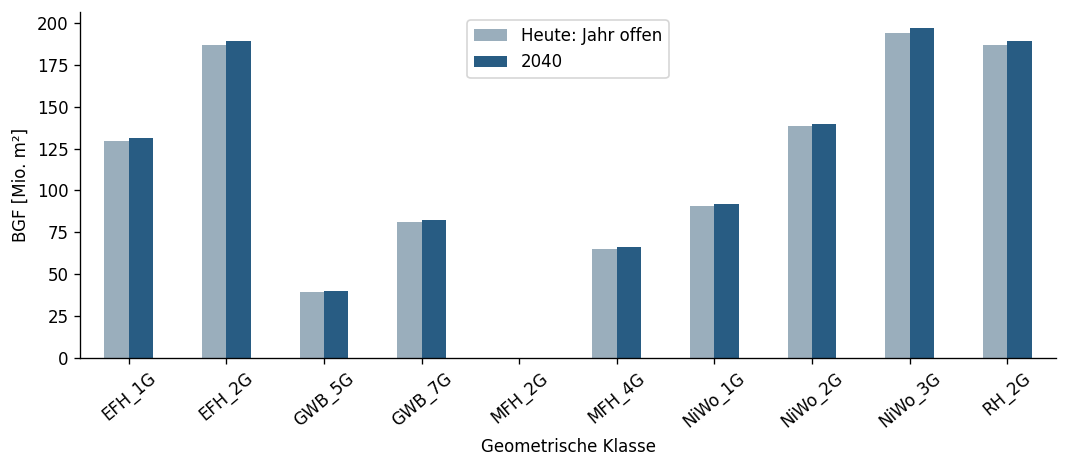

In [3]:
area_cols={'heute':'Nationale BGF heute','2040':'Nationale BGF 2040','2020':'BGF_2020_m2'}
for c in area_cols.values():
    assert data[c].dropna().ge(0).all()
areas=[]
for year,c in area_cols.items():
    areas.append({'Stand':year,'BGF [Mio. m²]':data[c].sum(min_count=1)/1e6,
                  'NGF [Mio. m²]':r*data[c].sum(min_count=1)/1e6,
                  'positiv':int(data[c].gt(0).sum()),'Null':int(data[c].eq(0).sum()),'fehlend':int(data[c].isna().sum())})
area_summary=pd.DataFrame(areas);display(area_summary)
for year,share in [('heute','Flächenanteil heute'),('2040','Flächenanteil 2040')]:
    # Quellanteile prüfen; nach redaktioneller Änderung absolute Flächen maßgeblich halten.
    expected=data[area_cols[year]]/data[area_cols[year]].sum(min_count=1)
    print(year,'max. Abweichung der gelieferten Anteilsfelder:',abs(data[share]-expected).max())
old=source['reduced']; old_area=pd.to_numeric(old.NGF_m2,errors='coerce')
area_audit=pd.DataFrame([
 {'Datensatz':'reduced (NGF, alter Stand)','NGF [Mio. m²]':old_area.sum(min_count=1)/1e6,'positiv':old_area.gt(0).sum(),'Null':old_area.eq(0).sum(),'fehlend':old_area.isna().sum()},
 {'Datensatz':'Strombed_estim heute (BGF × r)','NGF [Mio. m²]':r*data['Nationale BGF heute'].sum()/1e6,'positiv':data['Nationale BGF heute'].gt(0).sum(),'Null':data['Nationale BGF heute'].eq(0).sum(),'fehlend':data['Nationale BGF heute'].isna().sum()},
 {'Datensatz':'Strombed_estim 2040 (BGF × r)','NGF [Mio. m²]':r*data['Nationale BGF 2040'].sum()/1e6,'positiv':data['Nationale BGF 2040'].gt(0).sum(),'Null':data['Nationale BGF 2040'].eq(0).sum(),'fehlend':data['Nationale BGF 2040'].isna().sum()}])
display(area_audit)
old['Kern']=old['Scenario Name'].str.split('|').str[:3].str.join('|')
data['Kern']=data.Archetype.str.split('|').str[:3].str.join('|')
core=old.groupby('Kern').NGF_m2.sum(min_count=1).rename('reduced_NGF').to_frame().join(
    data.groupby('Kern')['Nationale BGF heute'].sum(min_count=1).mul(r).rename('neu_NGF_heute'))
core['Differenz_NGF']=core.neu_NGF_heute-core.reduced_NGF
core.to_csv(OUT/'flaechenvergleich_kern.csv')
statussum=data[['Bestand','Neubau','Sanierung']].sum(axis=1,min_count=3)
assert np.allclose(statussum[data['Nationale BGF 2040'].gt(0)],1)
status=pd.DataFrame([{'Zustand':c,'BGF 2040 [Mio. m²]':(data[c]*data['Nationale BGF 2040']).sum(min_count=1)/1e6} for c in ['Bestand','Neubau','Sanierung']])
display(status)
geometry_area=data.groupby('Geometrie')[['Nationale BGF heute','Nationale BGF 2040']].sum(min_count=1)/1e6
display(geometry_area)
fig,ax=plt.subplots(figsize=(9,4));geometry_area.plot.bar(ax=ax,color=['#9aaebc','#285c83'])
ax.set(ylabel='BGF [Mio. m²]',xlabel='Geometrische Klasse');ax.tick_params(axis='x',rotation=40)
ax.legend(['Heute: Jahr offen','2040']);fig.tight_layout();fig.savefig(OUT/'flaechen.png',dpi=180);plt.show()
area_audit.to_csv(OUT/'flaechenaudit.csv',index=False)

## 4. Strombedarf, Erzeugung und Stromsaldo {#sec-gebaeude-strom}

`Grid_to_building_min` ist **Netzbezug**, nicht der gesamte Strombedarf. Für die vorliegenden Varianten ohne Speicher/Flexibilität/MIV gilt:

$$e_{el,k}=e_{Netz,k}+e_{PV,direkt,k},\quad p_{PV,k}=e_{PV,direkt,k}+e_{PV,Export,k},$$
$$B_{el,y}=\sum_k A_{NGF,k,y}(p_{PV,k}-e_{el,k})=\sum_k A_{NGF,k,y}(e_{PV,Export,k}-e_{Netz,k}).$$

Beide Bilanzwege werden unabhängig verglichen. Der Direktverbrauch wird nicht zweimal als Deckung angerechnet. Heizung und Warmwasser enthalten bereits Hilfsstrom; für die Anwendungsgrafik wird dieser aus den jeweiligen Summen herausgelöst und zusammen mit Allgemeinstrom separat gezeigt. Beleuchtung und Nutzerstrom bleiben getrennt. Die Klimatisierungsnullen sind gelieferte Simulationswerte, keine nationale Annahme ohne Kühlbedarf.

Für einen spezifischen Kennwert $e_k$ gilt $E_y=\sum_k A_{NGF,k,y}e_k$ und $\bar e_y=E_y/\sum_k A_{NGF,k,y}$. Fehlende Kennwerte auf positiver Fläche lassen eine Vollbilanz offen; bekannte Teilmengen werden eigens ausgewiesen.

,Stand,Größe,kWh/(m² NGF a),GWh/a,PJ/a,fehlende BGF [m²],Flächen offen
6,2040,Strombedarf,42.376726,38192.572254,137.493260,0.0,False
7,2040,PV_Erzeugung,24.115993,21734.850532,78.245462,0.0,False
8,2040,Grid_to_building_min,34.898510,31452.733686,113.229841,0.0,False
9,2040,PV_total_direct,7.478216,6739.838568,24.263419,0.0,False
10,2040,PV_to_Egrid,16.637777,14995.011964,53.982043,0.0,False
11,2040,Stromsaldo,-18.260733,-16457.721722,-59.247798,0.0,False


,GWh/a
Heizung,7032.501102
Warmwasser,1351.416608
Kühlung,0.000000
Lüftung,1053.688634
Hilfs-/Allgemeinstrom,3179.587258
Beleuchtung,3986.780084
Geräte/IT,21588.598568


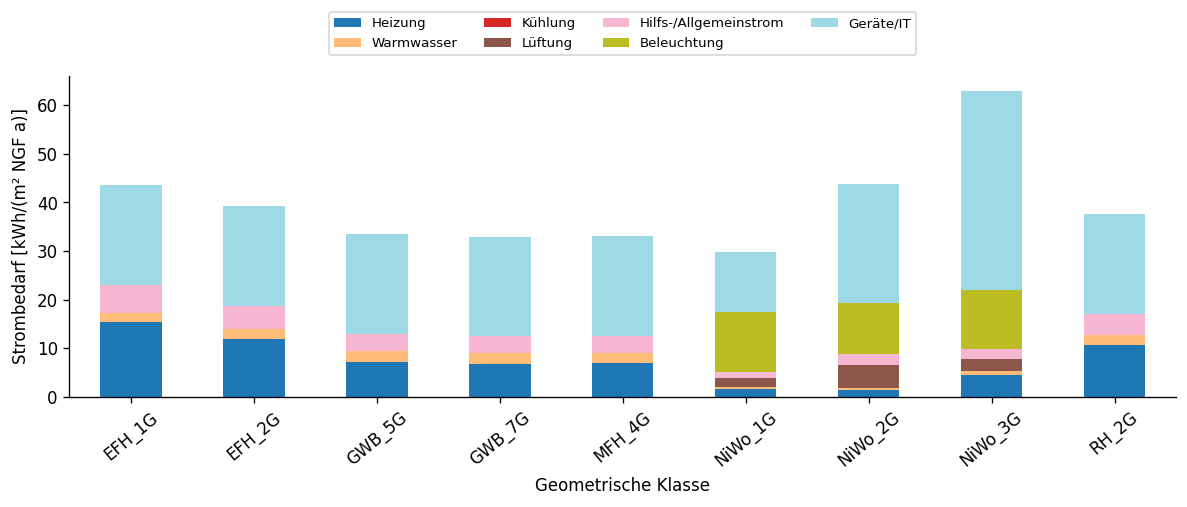

,Strombedarf,PV_Erzeugung,Stromsaldo
Geometrie,,,
EFH_1G,4564.515885,7984.573792,3420.057907
EFH_2G,5952.983278,5772.806937,-180.176341
GWB_5G,1070.918526,486.713588,-584.204938
GWB_7G,2163.824067,714.677751,-1449.146316
MFH_2G,0.000000,0.000000,0.000000
MFH_4G,1739.211896,1003.271527,-735.940369
NiWo_1G,2188.125328,0.000000,-2188.125328
NiWo_2G,4909.958277,0.000000,-4909.958277
NiWo_3G,9906.846278,0.000000,-9906.846278


In [4]:
for c in ['Batt_total_charge_input','EUIev_el','PV_total_flex','VRGrid_to_building','EUIdhwdirect_el']:
    assert np.allclose(data[c],0), f'Erweiterte Flusslogik erforderlich: {c}'
data['Strombedarf']=data.Grid_to_building_min+data.PV_total_direct
data['PV_Erzeugung']=data.PV_total_direct+data.PV_to_Egrid
data['Stromsaldo']=data.PV_Erzeugung-data.Strombedarf
np.testing.assert_allclose(data.Strombedarf,data.EUI_el_total,atol=1e-7)
np.testing.assert_allclose(data.PV_Erzeugung,data.PV_total,atol=1e-7)
np.testing.assert_allclose(data.Stromsaldo,data.PV_to_Egrid-data.Grid_to_building_min,atol=1e-8)
apps=pd.DataFrame({'Heizung':data.EUIh_el-data.EUIh_el_aux,
 'Warmwasser':data.EUIdhw_el-data.Edhw_aux_el,'Kühlung':data.EUIc_el-data.EUIc_el_aux,
 'Lüftung':data.EUIv_el,'Hilfs-/Allgemeinstrom':data.EUI_auxiliary+data.EUIh_el_aux+data.EUIc_el_aux+data.Edhw_aux_el,
 'Beleuchtung':data.EUI_lighting,'Geräte/IT':data.EUI_plugloads})
assert (apps.min()>=-1e-7).all()
np.testing.assert_allclose(apps.sum(axis=1,min_count=7),data.Strombedarf,atol=1e-7)
# Vollsummen bleiben bei fehlender positiver Fläche/Kennwert offen.
def aggregate(values, area):
    missing_area=area.isna().any()
    active=area.gt(0)
    covered=active & values.notna()
    known=(values[covered]*area[covered]*r).sum(min_count=1)
    missing=area[active & values.isna()].sum()
    return dict(kWh=known if not missing_area and missing==0 else np.nan,
                bekannte_kWh=known,fehlende_BGF_m2=missing,Flächen_offen=missing_area)
energy_records=[]
for year,c in area_cols.items():
    for metric in ['Strombedarf','PV_Erzeugung','Grid_to_building_min','PV_total_direct','PV_to_Egrid','Stromsaldo']:
        a=aggregate(data[metric],data[c]);energy_records.append({'Stand':year,'Größe':metric,
            'kWh/(m² NGF a)':a['kWh']/(data[c].sum(min_count=1)*r),
            'GWh/a':a['kWh']/1e6,'PJ/a':a['kWh']*3.6e-9,'fehlende BGF [m²]':a['fehlende_BGF_m2'],'Flächen offen':a['Flächen_offen']})
energy=pd.DataFrame(energy_records);display(energy[energy.Stand.eq('2040')])
weighted_apps=apps.mul(data['Nationale BGF 2040']*r,axis=0)
application_total=weighted_apps.sum(min_count=1)/1e6
display(application_total.rename('GWh/a').to_frame())
by_geometry=weighted_apps.groupby(data.Geometrie).sum(min_count=1).div((data['Nationale BGF 2040']*r).groupby(data.Geometrie).sum(),axis=0)
fig,ax=plt.subplots(figsize=(10,4.5));by_geometry.dropna(how='all').plot.bar(stacked=True,ax=ax,colormap='tab20')
ax.set(ylabel='Strombedarf [kWh/(m² NGF a)]',xlabel='Geometrische Klasse');ax.tick_params(axis='x',rotation=40)
ax.legend(loc='upper center',bbox_to_anchor=(.5,1.22),ncol=4,fontsize=8);fig.tight_layout();fig.savefig(OUT/'strom_anwendungen.png',dpi=180);plt.show()
geom_energy=data[['Strombedarf','PV_Erzeugung','Stromsaldo']].mul(data['Nationale BGF 2040']*r,axis=0).groupby(data.Geometrie).sum(min_count=1)/1e6
display(geom_energy)
energy.to_csv(OUT/'strombilanz.csv',index=False);by_geometry.to_csv(OUT/'strom_anwendungen_spezifisch.csv');geom_energy.to_csv(OUT/'strombilanz_geometrie.csv')

## 5. Endenergiebilanz nach Energieträgern und Anwendungen {#sec-gebaeude-endenergie}

Die elektrische Heizung ist nicht die gesamte Wärmeversorgung. Die Quelle enthält Fernwärme, Erdgas, Biomasse und „other“. **Öl wird aus `EUI_other` nur für Schlüssel mit Heizsystem `Oel` herausgelöst**. Ein anderer „other“-Betrag bleibt sonstige thermische Endenergie. Die Anwendungsaufteilung stammt aus den zugehörigen `EUIh_*`, `EUIdhw_*` und `EUIc_other`-Spalten, nicht aus angenommenen Wirkungsgraden.

$$E_{i,y}=\sum_k A_{NGF,k,y}\,e_{i,k},\qquad E_{End,y}=E_{el,y}+\sum_{i\ne el}E_{i,y}.$$

Der Bruttostrombedarf enthält lokal genutzten PV-Strom. Die alternativ ausgewiesene externe Lieferung enthält nur Netzbezug plus thermische Energieträger. Umweltwärme ist in diesen gelieferten Trägerkennwerten nicht als zusätzliche Endenergielieferung enthalten; diese Abgrenzung ist beim Vergleich mit nationalen Statistiken zu beachten.

,Träger,Anwendung,GWh/a
0,Fernwärme,Heizung,25469.010583
1,Fernwärme,Warmwasser,2919.601453
2,Gas,Heizung,19758.732851
3,Gas,Warmwasser,1539.236595
4,Biomasse,Heizung,17839.911366
5,Biomasse,Warmwasser,1398.711472
6,Sonstige inkl. Öl,Heizung,15341.777127
7,Sonstige inkl. Öl,Warmwasser,911.609076
8,Sonstige inkl. Öl,Kühlung,0.000000


,Stand,Träger,kWh/(m² NGF a),GWh/a,PJ/a
6,2040,Strom (Bruttobedarf),42.376726,38192.572254,137.493260
7,2040,Fernwärme,31.498702,28388.612036,102.199003
8,2040,Gas,23.631250,21297.969446,76.672690
9,2040,Biomasse,21.346293,19238.622838,69.259042
10,2040,Öl,18.034012,16253.386204,58.512190
11,2040,Sonstige thermisch,0.000000,0.000000,0.000000


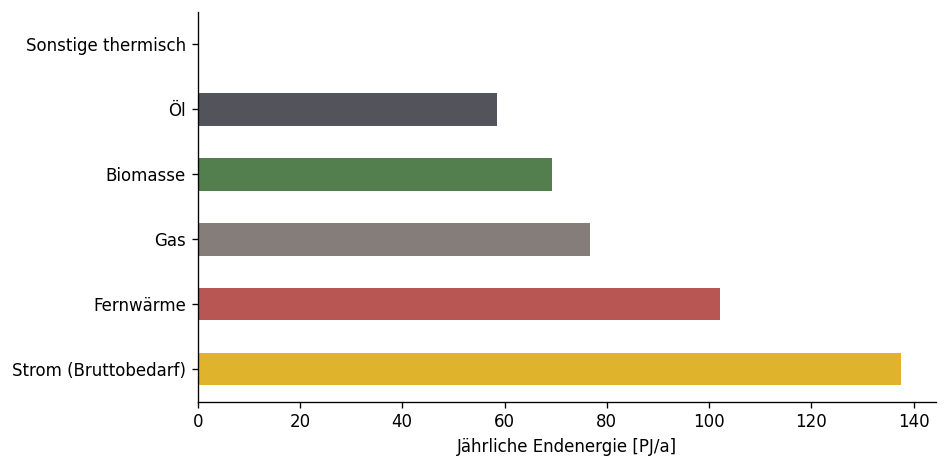

In [5]:
carriers=pd.DataFrame({'Strom (Bruttobedarf)':data.Strombedarf,'Fernwärme':data.EUI_district_heating,
 'Gas':data.EUI_natural_gas,'Biomasse':data.EUI_biomass,
 'Öl':data.EUI_other.where(data.Heizung.eq('Oel'),0),
 'Sonstige thermisch':data.EUI_other.where(~data.Heizung.eq('Oel'),0)})
thermal_apps=[]
for carrier,suffix in [('Fernwärme','district_heating'),('Gas','natural_gas'),('Biomasse','biomass'),('Sonstige inkl. Öl','other')]:
    comps={'Heizung':data['EUIh_'+suffix],'Warmwasser':data['EUIdhw_'+suffix]}
    if suffix=='other': comps['Kühlung']=data.EUIc_other
    np.testing.assert_allclose(sum(comps.values()),data['EUI_'+suffix],atol=1e-7)
    for app,series in comps.items():
        thermal_apps.append({'Träger':carrier,'Anwendung':app,'GWh/a':aggregate(series,data['Nationale BGF 2040'])['kWh']/1e6})
display(pd.DataFrame(thermal_apps))
ee=[]
for year,c in area_cols.items():
    for carrier in carriers:
        a=aggregate(carriers[carrier],data[c]);ee.append({'Stand':year,'Träger':carrier,
            'kWh/(m² NGF a)':a['kWh']/(data[c].sum(min_count=1)*r),'GWh/a':a['kWh']/1e6,'PJ/a':a['kWh']*3.6e-9})
endenergy=pd.DataFrame(ee);display(endenergy[endenergy.Stand.eq('2040')])
endenergy.to_csv(OUT/'endenergiebilanz.csv',index=False)
pd.DataFrame(thermal_apps).to_csv(OUT/'thermische_anwendungen_2040.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));endenergy[endenergy.Stand.eq('2040')].set_index('Träger')['PJ/a'].plot.barh(ax=ax,color=['#dfb42c','#b85654','#847d7a','#527f4d','#53545b','#9b8c70'])
ax.set(xlabel='Jährliche Endenergie [PJ/a]',ylabel='');fig.tight_layout();fig.savefig(OUT/'endenergie.png',dpi=180);plt.show()

## 6. Primärenergie: gelieferter Bewertungsstand {#sec-gebaeude-pe}

Die physische Import-/Exportbilanz lautet $B_{PE,y}=\sum_k A_{NGF,k,y}(PEI_{export,k}-PEI_{import,k})$. Die gelieferten `PEI`-Werte werden aggregiert, **ohne** virtuelle Kontextwerte einzurechnen. Ihre Konsistenz wird gegen Netzstrom-PE plus die vier thermischen PE-Komponenten geprüft.

Die sektorale Zuordnung 2040 bleibt eine Endenergieaufgabe. Die nachgelagerte PE-Bewertung soll die Kompatibilität mit heutigen Bewertungsverfahren herstellen, nicht die PE-Intensität des Energiesystems 2040 prognostizieren. Die Datei liefert bereits zeit-/typabhängig gewichtete PEI; ihr genauer Faktorensatz und dessen Bezugsjahr sind noch zu bestätigen. Ein pauschaler Jahresfaktor würde diese Ergebnisse nicht reproduzieren. Deshalb werden **implizite effektive Faktoren** $f_{i,k}=PEI_{i,k}/e_{i,k}$ nur diagnostisch ausgewiesen. Bei Nenner null bleibt der Quotient leer. Die Tabelle `PE_Faktoren` bereitet explizite, quellenbelegte Jahresfaktoren/Absenkpfade vor und bleibt zunächst leer.

In [6]:
thermal_pe=data[['PEI_district_heating','PEI_natural_gas','PEI_biomass','PEI_other']].sum(axis=1,min_count=4)
np.testing.assert_allclose(data.PEI_import,data.PEI_grid_import+thermal_pe,atol=1e-7)
data['PE_Saldo']=data.PEI_export-data.PEI_import
pe_records=[]
for year,c in area_cols.items():
    for metric in ['PEI_grid_import','PEI_import','PEI_export','PE_Saldo']:
        a=aggregate(data[metric],data[c]);pe_records.append({'Stand':year,'Größe':metric,'GWh_PE/a':a['kWh']/1e6,'PJ_PE/a':a['kWh']*3.6e-9})
primary=pd.DataFrame(pe_records);display(primary[primary.Stand.eq('2040')])
implicit=[]
for carrier,ee_col,pe_col in [('Netzstrom','Grid_to_building_min','PEI_grid_import'),('PV-Export','PV_to_Egrid','PEI_export'),
 ('Fernwärme','EUI_district_heating','PEI_district_heating'),('Gas','EUI_natural_gas','PEI_natural_gas'),
 ('Biomasse','EUI_biomass','PEI_biomass'),('Sonstige inkl. Öl','EUI_other','PEI_other')]:
    f=data[pe_col].div(data[ee_col].where(data[ee_col].ne(0)))
    implicit.append(pd.DataFrame({'Archetype':data.Archetype,'Träger':carrier,'f_PE_effektiv':f,'Bezugsjahr':params['jahr_pe_bewertung']}))
implicit=pd.concat(implicit,ignore_index=True);display(implicit.groupby('Träger').f_PE_effektiv.agg(['min','max']))
primary.to_csv(OUT/'primaerenergiebilanz.csv',index=False);implicit.to_csv(OUT/'pe_faktoren_effektiv.csv',index=False)

,Stand,Größe,GWh_PE/a,PJ_PE/a
4,2040,PEI_grid_import,59495.871149,214.185136
5,2040,PEI_import,137528.611871,495.103003
6,2040,PEI_export,23816.432121,85.739156
7,2040,PE_Saldo,-113712.179750,-409.363847


,min,max
Träger,,
Biomasse,1.130000,1.130000
Fernwärme,0.330000,1.681410
Gas,1.100000,1.100000
Netzstrom,1.815914,2.027190
PV-Export,1.437099,1.610513
Sonstige inkl. Öl,1.200000,1.200000


## 7. GFZ-Zuordnung, Flächengewichtung und Dichte-Erwartungswert {#sec-gebaeude-gfz}

Die Zuordnung aus `zuordnung_gfz` wird auf die Kategorien der vorhandenen GFZ-Hochrechnung 2021 übersetzt. Die Quellgruppen mit einer bzw. zwei Wohnungen haben identische Zuordnungen und werden **einmal** auf die zusammengefasste GFZ-Gruppe „Ein- und Zweifamilienhäuser“ angewendet. Die 50/50-Aufteilung zwischen EFH_2G und RH_2G wird übernommen. Die vom Auftraggeber am 23.10.2026 bestätigte Regel lautet: **Eine einzige Zielklasse erhält 100 %; die zweite Zielspalte dient nur einer Aufteilung.** Die aktualisierte Excel enthält diese 100-%-Werte nun explizit. Es sind keine fehlenden Quellanteile mehr zu ergänzen. Die Regel bleibt für zukünftige Einzelzuordnungen implementiert und wird im Audit protokolliert. MFH_2G hat keine Zuordnung und keine positive Fläche; sein Erwartungswert bleibt leer. Es wird kein Ersatz aus anderen Gebäudetypen erfunden.

Aus GFZ-Referenzfläche $R_{u,g,j}$ und Zuordnungsanteil $z_{u,g,k}$ entsteht
$$R_{k,j}=\sum_{u,g}z_{u,g,k}R_{u,g,j},\qquad s_{j|k}=R_{k,j}/\sum_j R_{k,j}.$$
Diese **bedingte Verteilung** wird auf die unabhängig gelieferte Typenfläche übertragen: $A_{k,j}^{2040}=A_k^{2040}s_{j|k}$. Die Referenzfläche wird nicht als zusätzliche nationale Fläche addiert. Die Annahme ist, dass Hüll- und Technikvarianten derselben Geometrie die gleiche Dichteverteilung besitzen; eine räumliche Änderung bis 2040 ist damit noch nicht modelliert. Die vorhandene freigegebene GFZ-Ersatzregel (1,696 % Referenz-BGF) bleibt unverändert.

Als vorläufige historische **elektrische** Referenz wird die Tabellenparametrisierung der PED-Typen aus Schneider et al. (2023), Gl. 7/Tabelle 5, verwendet [@schneider2023context]:
$$c_D^{el}(d)=-\min\left(\frac{30{,}4}{d+0{,}15}-26{,}4;62\right)\quad[kWh/(m^2\,BGF\,a)].$$
Die Originaltabelle enthält widersprüchliche EE-/PE-Einheitenbeschriftungen (insbesondere bei der Begrenzung). Hier wird die elektrische Tabellenlesart als **provisorischer Referenzstand** dokumentiert; daraus entsteht keine neu freigegebene Anforderung. Die bereits PE-gewichteten Kontextwerte der Einzelsimulation werden nicht als EE ausgegeben und nicht zur GFZ-Hochrechnung benutzt. Positive $c_D$ sind virtuelle Gutschriften, negative zusätzliche Anforderungen.

$$\mathbb E_k[GFZ]=\sum_j s_{j|k}d_j,\qquad\mathbb E_k[c_D]=\sum_j s_{j|k}c_D(d_j).$$
Wegen der Nichtlinearität gilt im Allgemeinen $\mathbb E[c_D(d)]\ne c_D(\mathbb E[d])$. NGF-spezifische Kontextwerte ergeben sich durch Division durch $r$, noch **ohne PE-Umrechnung**. Die Verteilung des Kontextwerts wird für jeden GFZ-Bin exportiert; die Typenerwartung dient der späteren Kalibrierung, nicht einer automatischen Gutschrift für alle Typen.

Nach bestätigter Einzelzielregel ergänzte leere Anteile: 0 Quellzeilen
Davon betroffene Referenz-BGF [%]: 0.0


,GFZ_Mittel,c_D_EE_BGF,Referenz_BGF,c_D_EE_NGF,c_am_GFZ_Mittel
Geometrie,,,,,
EFH_1G,0.317942,-41.630722,1.297227e+08,-52.038402,-38.565338
EFH_2G,0.614984,-22.798103,1.724298e+08,-28.497629,-13.339407
GWB_5G,2.266322,8.965535,3.707040e+07,11.206919,13.818897
GWB_7G,4.000472,16.439657,7.518450e+07,20.549571,19.075532
MFH_4G,1.541462,1.431515,6.056382e+07,1.789394,8.427382
NiWo_1G,0.490604,-29.353340,8.710480e+07,-36.691675,-21.055233
NiWo_2G,0.874806,-13.124038,1.368895e+08,-16.405047,-3.264162
NiWo_3G,2.183130,3.923841,1.875395e+08,4.904801,13.370295
RH_2G,0.614984,-22.798103,1.724298e+08,-28.497629,-13.339407


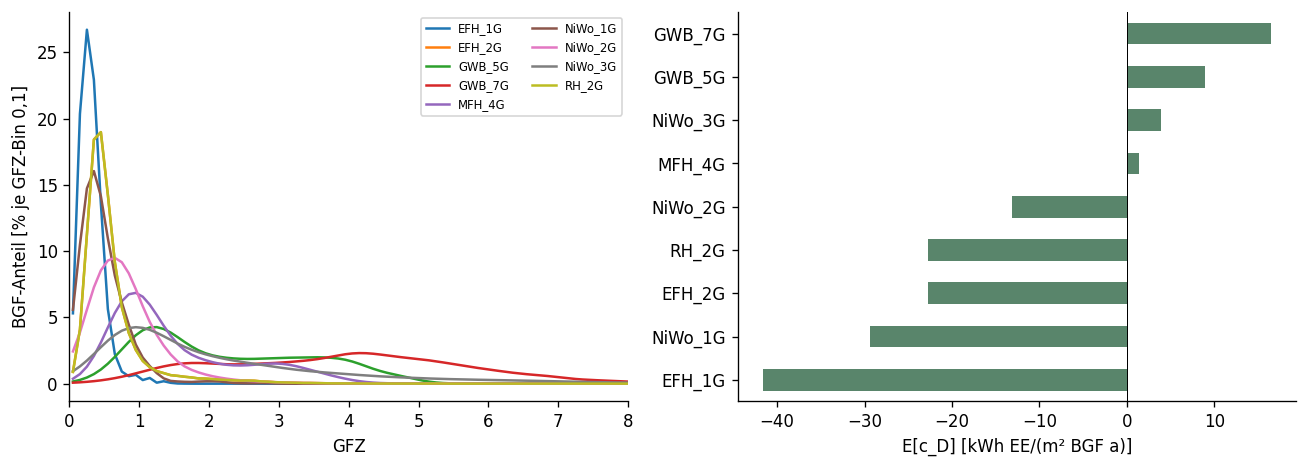

In [7]:
mapping=inputs['GFZ_Zuordnung'].copy()
use_map={'Gebäude für Gemeinschaften':'Gemeinschaftsgebäude','Hotels und ähnliche Gebäude':'Hotels o.Ä.',
 'Bürogebäude':'Büronutzung','Groß- und Einzelhandelsgebäude':'Groß- und Einzelhandelsgebäude',
 'Gebäude des Verkehrs- und Nachrichtenwesens':'Verkehrs- und Nachrichtenwesen','Industrie- und Lagergebäude':'Industrie und Lagerung',
 'Gebäude für Kultur- und Freizeitzwecke sowie des Bildungs- und Gesundheitswesens':'Kultur, Freizeit, Bildung und Gesundheit',
 'Wohngebäude mit einer Wohnung':'Ein- und Zweifamilienhäuser','Wohngebäude mit zwei Wohnungen':'Ein- und Zweifamilienhäuser',
 'Wohngebäude mit drei und mehr Wohnungen':'Mehrfamilienhaus'}
mapping['GWR_Nutzung']=mapping.Nutzung.map(use_map); assert mapping.GWR_Nutzung.notna().all()
mapping['GK']=mapping.Geschoss.str.replace(' Geschoße','',regex=False).str.replace(' Geschoß','',regex=False).replace({'6 bis 10':'6-10','11 und mehr':'11+'})
mapping['Einzelziel_ergänzt']=mapping.Anteil1.isna() & mapping.Archetype1.notna() & mapping.Archetype2.isna()
if params['single_target_missing_share']==1:
    mapping.loc[mapping['Einzelziel_ergänzt'],'Anteil1']=1.0
mapping.to_csv(OUT/'gfz_zuordnung_audit.csv',index=False)
# Doppelte Statistiknutzungen nur zusammenführen, wenn ihre Regeln identisch sind.
for key,group in mapping.groupby(['GWR_Nutzung','GK']):
    assert len(group[['Anteil1','Archetype1','Anteil2','Archetype2']].drop_duplicates())==1,key
unique=mapping.drop_duplicates(['GWR_Nutzung','GK'])
long=[]
for _,row in unique.iterrows():
    for n in [1,2]:
        if pd.notna(row[f'Archetype{n}']):
            long.append({'GWR_Nutzung':row.GWR_Nutzung,'GK':row.GK,'Geometrie':row[f'Archetype{n}'],'Anteil':row[f'Anteil{n}']})
links=pd.DataFrame(long)
assert links.Anteil.notna().all(), 'GFZ-Anteile offen; Einzelzielregel oder Eingaben prüfen'
assert links.Anteil.between(0,1).all()
np.testing.assert_allclose(links.groupby(['GWR_Nutzung','GK']).Anteil.sum(),1)
gfz=pd.read_csv(ROOT/'Berechnungen/gfz_at/outputs/recalculated/gfz_distribution_by_province_use_storeys.csv',dtype={'GK':str})
joined=gfz.merge(links,on=['GWR_Nutzung','GK'],how='left',indicator=True)
assert joined['_merge'].eq('both').all()
joined['zugeordnete_BGF']=joined.BGF_m2*joined.Anteil
np.testing.assert_allclose(joined.zugeordnete_BGF.sum(),gfz.BGF_m2.sum(),rtol=1e-12)
bins=joined.groupby(['Geometrie','GFZ'],as_index=False).zugeordnete_BGF.sum()
bins['s']=bins.zugeordnete_BGF/bins.groupby('Geometrie').zugeordnete_BGF.transform('sum')
bins['c_D_EE_BGF']=-np.minimum(float(params['density_f_res'])/(bins.GFZ+float(params['density_dx']))-float(params['density_f_ed']),float(params['density_cutoff']))
bins['c_D_EE_NGF']=bins.c_D_EE_BGF/r
bins['gew_GFZ']=bins.GFZ*bins.s; bins['gew_c']=bins.c_D_EE_BGF*bins.s
density=bins.groupby('Geometrie').agg(GFZ_Mittel=('gew_GFZ','sum'),c_D_EE_BGF=('gew_c','sum'),Referenz_BGF=('zugeordnete_BGF','sum'))
density['c_D_EE_NGF']=density.c_D_EE_BGF/r
density['c_am_GFZ_Mittel']=-np.minimum(float(params['density_f_res'])/(density.GFZ_Mittel+float(params['density_dx']))-float(params['density_f_ed']),float(params['density_cutoff']))
data=data.merge(density[['GFZ_Mittel','c_D_EE_BGF','c_D_EE_NGF']],left_on='Geometrie',right_index=True,how='left',validate='many_to_one')
assert data.loc[data['Nationale BGF 2040'].gt(0),'GFZ_Mittel'].notna().all()
print('Nach bestätigter Einzelzielregel ergänzte leere Anteile:',int(mapping['Einzelziel_ergänzt'].sum()),'Quellzeilen')
affected=unique.loc[unique['Einzelziel_ergänzt'],['GWR_Nutzung','GK']]
affected_area=gfz.merge(affected,on=['GWR_Nutzung','GK']).BGF_m2.sum()
print('Davon betroffene Referenz-BGF [%]:',100*affected_area/gfz.BGF_m2.sum())
display(density)
matrix=data.loc[data['Nationale BGF 2040'].gt(0),['Archetype','Geometrie','Nationale BGF 2040']].merge(bins[['Geometrie','GFZ','s','c_D_EE_BGF']],on='Geometrie',validate='many_to_many')
matrix['BGF_2040_m2']=matrix['Nationale BGF 2040']*matrix.s
by_type=matrix.groupby('Archetype').BGF_2040_m2.sum()
np.testing.assert_allclose(by_type,data.set_index('Archetype').loc[by_type.index,'Nationale BGF 2040'],rtol=1e-12)
matrix[['Archetype','Geometrie','GFZ','s','BGF_2040_m2','c_D_EE_BGF']].to_csv(OUT/'typologie_gfz_2040.csv.gz',index=False,compression='gzip')
bins.to_csv(OUT/'gfz_kontext_verteilungen.csv',index=False);density.to_csv(OUT/'dichte_erwartungswerte.csv')
data[['Archetype','Geometrie','GFZ_Mittel','c_D_EE_BGF','c_D_EE_NGF','Nationale BGF 2040']].to_csv(OUT/'typologie_dichte.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,g in bins.groupby('Geometrie'):
    axes[0].plot(g.GFZ,g.s*100,label=name)
axes[0].set(xlim=(0,8),xlabel='GFZ',ylabel='BGF-Anteil [% je GFZ-Bin 0,1]');axes[0].legend(fontsize=7,ncol=2)
density.c_D_EE_BGF.sort_values().plot.barh(ax=axes[1],color='#59856b');axes[1].axvline(0,color='black',linewidth=.6)
axes[1].set(xlabel='E[c_D] [kWh EE/(m² BGF a)]',ylabel='');fig.tight_layout();fig.savefig(OUT/'gfz_dichte.png',dpi=180);plt.show()

## 8. Abgleich mit der sektoralen Allokation und Grenzen {#sec-gebaeude-abgleich}

Zunächst wird der **betriebliche Stromsaldo** mit Gebäude-PV minus Gebäudestrom aus der UBA-Allokation verglichen. Erst danach werden identische MIV-Mengen auf beiden Seiten einbezogen:
$$B_{BU,erweitert}=B_{BU,Betrieb}+E_{MIV,Budget}-E_{MIV,Bedarf}.$$
Das verändert die Differenz nicht. Zusätzliche virtuelle Dichtewerte werden hier **nicht** addiert: Sie würden ohne freigegebene PEQ-Flächenanteile und Zielwertdefinition eine neue Bilanzgrenze erzeugen. Ebenso dürfen thermische Endenergien nicht kommentarlos mit einem reinen Stromziel verglichen werden.

Der Pool enthält durchgehend PV30/noFlex und weiterhin fossile Wärmeversorgung im Zieljahr. Ein Abstand zu Transition ist daher ein **inhaltlicher Szenariobefund**, kein Rundungsfehler, der durch Skalieren zu beseitigen wäre. Der PEQ-Anteil ist in der Reinschrift als offenes Eingabefeld vorbereitet. Die Zahl allein, etwa ein positiver Stromsaldo eines Typs, belegt keine Standardkonformität.

In [8]:
allocation_path=ROOT/'Berechnungen/sektorenmodell/outputs/allokation/allokation.json'
allocation=json.loads(allocation_path.read_text(encoding='utf-8')); top=allocation['result']
def val(metric):
    return float(energy.loc[energy.Stand.eq('2040') & energy['Größe'].eq(metric),'PJ/a'].iloc[0])
operating=val('Stromsaldo')
extended=operating+top['miv_budget_pj']-top['miv_demand_pj']
comparison=pd.DataFrame([
 {'Größe':'PV-Erzeugung','Bottom-up [PJ/a]':val('PV_Erzeugung'),'Top-down [PJ/a]':top['building_pv_pj']},
 {'Größe':'Gebäudestrombedarf','Bottom-up [PJ/a]':val('Strombedarf'),'Top-down [PJ/a]':top['building_pv_pj']-top['building_operation_pj']},
 {'Größe':'Betrieblicher Stromsaldo','Bottom-up [PJ/a]':operating,'Top-down [PJ/a]':top['building_operation_pj']},
 {'Größe':'Saldo einschließlich MIV','Bottom-up [PJ/a]':extended,'Top-down [PJ/a]':top['building_target_pj']}])
comparison['Differenz [PJ/a]']=comparison['Bottom-up [PJ/a]']-comparison['Top-down [PJ/a]']
display(comparison)
assert np.isclose(extended-top['building_target_pj'],operating-top['building_operation_pj'])
comparison.to_csv(OUT/'abgleich_allokation.csv',index=False)
print('PEQ-Anteile offen:',data.PEQ_Anteil_2040.isna().sum(),'von',len(data))
sensitivity=pd.DataFrame([{'NGF/BGF':ratio,'Strombedarf [PJ/a]':val('Strombedarf')*ratio/r,'Stromsaldo [PJ/a]':operating*ratio/r} for ratio in [.75,.8,.85]])
display(sensitivity)

,Größe,Bottom-up [PJ/a],Top-down [PJ/a],Differenz [PJ/a]
0,PV-Erzeugung,78.245462,149.0,-70.754538
1,Gebäudestrombedarf,137.493260,108.0,29.493260
2,Betrieblicher Stromsaldo,-59.247798,41.0,-100.247798
3,Saldo einschließlich MIV,-107.247798,-7.0,-100.247798


PEQ-Anteile offen: 900 von 900


,NGF/BGF,Strombedarf [PJ/a],Stromsaldo [PJ/a]
0,0.75,128.899931,-55.544811
1,0.80,137.493260,-59.247798
2,0.85,146.086589,-62.950786


## 9. Ergebnisexport, Kontrollen und Fortschreibungsbedarf

Die kleine NGF/BGF-Variation illustriert die Bedeutung des Flächenbezugs; sie ist keine Optimierung. Die Ausführung prüft eindeutige Schlüssel, Quell-Cache-Konsistenz, Anwendungen, PV- und Strombilanz, thermische Teilbilanzen, PE-Importkomponenten, nicht doppelte GFZ-Zuordnung und Erhalt jeder positiven Typenfläche in der GFZ-Matrix.

Für die Fortschreibung benötigt werden: das genaue Bezugsjahr „heute“ und gegebenenfalls echte 2020-Flächen; Herleitung der Flächenentwicklung und Bestands-/Sanierungsanteile; Bestätigung von NGF/BGF je Typ; Definition und Anteil der PEQ-Klassen; alternative PV-/Flexibilitätsausstattungen; Prüfung der fossil beheizten Flächen 2040; Faktorversion der gelieferten PEI; eindeutige EE-Einheiten des historischen Dichte-Referenzstands. Die Einzelzielregel der GFZ-Zuordnung ist inzwischen bestätigt und in der Quelle ergänzt. Erst nach Klärung der noch offenen methodischen Punkte kann die nationale Zielwertfunktion neu kalibriert werden. Die aktuellen Ergebnisse sind nachvollziehbare **Pool-Ergebnisse**, keine Bestätigung der Klimaneutralität des Gebäudesektors.

In [9]:
# Null ist eine Zahl, unbekannt bleibt unbekannt: unabhängige kleine Regressionen.
assert np.isnan(aggregate(pd.Series([1.,np.nan]),pd.Series([1.,1.]))['kWh'])
assert aggregate(pd.Series([1.,np.nan]),pd.Series([1.,0.]))['kWh']==r
assert np.isnan(aggregate(pd.Series([1.,2.]),pd.Series([1.,np.nan]))['kWh'])
assert energy.loc[energy.Stand.eq('2020'),'PJ/a'].isna().all() if data.BGF_2020_m2.isna().all() else True
table=geometry_area.rename(columns={'Nationale BGF heute':'BGF heute [Mio. m²]','Nationale BGF 2040':'BGF 2040 [Mio. m²]'}).reset_index()
table=table.merge(density[['GFZ_Mittel','c_D_EE_BGF']].reset_index(),on='Geometrie',how='left')
(GEN/'gebaeude-typologien.qmd').write_text(markdown_table(table,'Gelieferte Flächen und BGF-gewichtete Dichte-Erwartungswerte. Heute: Bezugsjahr offen; Dichtefunktion vorläufig in elektrischer Energie.','tbl-gebaeude-typologien'),encoding='utf-8')
(GEN/'gebaeude-strom.qmd').write_text(markdown_table(energy.loc[energy.Stand.eq('2040'),['Größe','kWh/(m² NGF a)','GWh/a','PJ/a']],'Strombilanz 2040 aus den gelieferten Typenkennwerten bei NGF/BGF = '+str(r)+'.','tbl-gebaeude-strom'),encoding='utf-8')
(GEN/'gebaeude-endenergie.qmd').write_text(markdown_table(endenergy.loc[endenergy.Stand.eq('2040')].drop(columns='Stand'),'Endenergie 2040 nach Energieträgern. Strom enthält PV-Direktverbrauch; sonstige thermische Energie wird separat geführt.','tbl-gebaeude-endenergie'),encoding='utf-8')
(GEN/'gebaeude-abgleich.qmd').write_text(markdown_table(comparison,'Vergleich bei gleichen elektrischen Bilanzgrenzen; Top-down-Zuordnungen bleiben vorläufig.','tbl-gebaeude-abgleich'),encoding='utf-8')
(GEN/'gebaeude-status.qmd').write_text(markdown_table(status,'Flächengewichtete Zuordnung zu Bestand, Neubau und Sanierung im Zieljahr.','tbl-gebaeude-status'),encoding='utf-8')
(GEN/'gebaeude-pe.qmd').write_text(markdown_table(primary.loc[primary.Stand.eq('2040')].drop(columns='Stand'),'Gelieferter PE-Bewertungsstand; Faktorversion und Bezugsjahr noch zu bestätigen, ohne virtuelle Kontextwerte.','tbl-gebaeude-pe'),encoding='utf-8')
summary={'provenance':provenance,'allocation_sha256':sha256(allocation_path),'ngf_bgf':r,
 'type_count':len(data),'positive_types_2040':int(data['Nationale BGF 2040'].gt(0).sum()),
 'bgf_2040_m2':float(data['Nationale BGF 2040'].sum()),'bgf_today_m2':float(data['Nationale BGF heute'].sum()),
 'electricity_demand_pj':val('Strombedarf'),'pv_pj':val('PV_Erzeugung'),'electricity_balance_pj':operating,
 'extended_balance_pj':extended,'gap_topdown_pj':extended-top['building_target_pj'],
 'single_target_missing_share_rows':int(mapping['Einzelziel_ergänzt'].sum()),
 'affected_reference_area_pct':100*affected_area/gfz.BGF_m2.sum(),
 'pe_balance_pj':float(primary.loc[primary.Stand.eq('2040') & primary['Größe'].eq('PE_Saldo'),'PJ_PE/a'].iloc[0]),
 'controls':'All assertions passed; source values are not an independently rerun PEExcel simulation.'}
(OUT/'validation.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
data.to_csv(OUT/'typen_ergebnisse.csv',index=False)
area_summary.to_csv(OUT/'flaechenbilanz.csv',index=False)
status.to_csv(OUT/'zustandsflaechen_2040.csv',index=False)
print(json.dumps(summary,ensure_ascii=False,indent=2))

{
  "provenance": {
    "source_sha256": "b032c1bd7148b0bdac8541196a1eaa7fc58f538f87912e1f2714af88ac80a7cd",
    "input_sha256": "cd09efbfbea7bc7e8cfd82b07146f72c6f3712d3a381625532b14c947dd75bc1",
    "gfz_sha256": "b17c1f98b6104a5b8ed6da4fe436ebff14d2f7708cc2043860d166b17d3f1c3b"
  },
  "allocation_sha256": "0db04e742493fd5d244b727c30b215703bacbd9c5954444bc3d131dd2024aaeb",
  "ngf_bgf": 0.8,
  "type_count": 900,
  "positive_types_2040": 603,
  "bgf_2040_m2": 1126578658.428,
  "bgf_today_m2": 1112340697.5,
  "electricity_demand_pj": 137.49326011458797,
  "pv_pj": 78.24546191661419,
  "electricity_balance_pj": -59.24779819797377,
  "extended_balance_pj": -107.24779819797376,
  "gap_topdown_pj": -100.24779819797376,
  "single_target_missing_share_rows": 0,
  "affected_reference_area_pct": 0.0,
  "pe_balance_pj": -409.3638470994995,
  "controls": "All assertions passed; source values are not an independently rerun PEExcel simulation."
}
